[14.3783222]
[14.37536009]
[14.52617153]
[14.51426849]
[14.61633124]
[14.45526156]
[14.40335079]
[14.14832828]
[13.97986699]
[13.71835467]
[13.48635327]
[13.25428121]
[12.99278425]
[12.79528802]
[12.52560943]
[12.35759173]
[12.09391963]
[11.94844506]
[11.70025271]
[11.57135333]
[11.34455593]
[11.22796382]
[11.02570355]
[10.91881102]
[10.74211332]
[10.64364326]
[10.49198407]
[10.40156765]
[10.27334863]
[10.19110203]
[10.08403294]
[10.01018498]
[9.92158252]
[9.85619039]
[9.78321018]
[9.72599049]
[9.66581037]
[9.61609685]
[9.56606508]
[9.52287899]
[9.48063066]
[9.44282419]
[9.40636077]
[9.37277831]
[9.34050283]
[9.31011155]
[9.28081799]
[9.252781]
[9.22560668]
[9.19929876]
[9.1736558]
[9.14863912]
[9.12414184]
[9.10012349]
[9.07652441]
[9.05331276]
[9.03045303]
[9.007922]
[8.98569682]
[8.96376049]
[8.94209698]
[8.92069328]
[8.8995372]
[8.87861825]
[8.85792654]
[8.83745323]
[8.81718992]
[8.79712892]
[8.77726292]
[8.7575851]
[8.73808899]
[8.71876849]
[8.69961781]
[8.68063146]
[8.66180423]
[

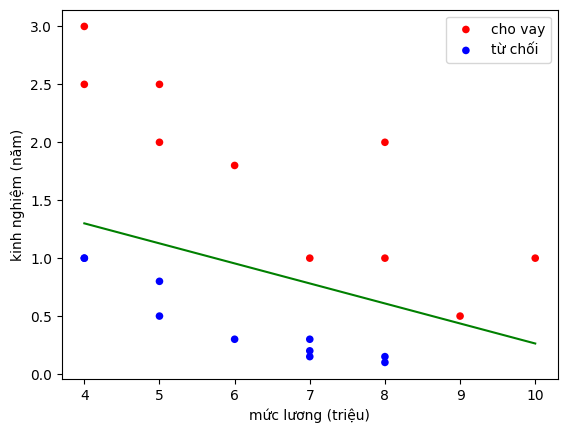

In [ ]:
#Lab2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Hàm sigmoid
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# Load data từ file csv
data = pd.read_csv('/content/dataset (1).csv').values
N, d = data.shape
x = data[:, 0:d-1].reshape(-1, d-1)
y = data[:, 2].reshape(-1, 1)

# Vẽ data bằng scatter
x_cho_vay = x[y[:,0]==1]
x_tu_choi = x[y[:,0]==0]

plt.scatter(x_cho_vay[:, 0], x_cho_vay[:, 1], c='red', edgecolors='none', s=30, label='cho vay')
plt.scatter(x_tu_choi[:, 0], x_tu_choi[:, 1], c='blue', edgecolors='none', s=30, label='từ chối')
plt.legend(loc=1)
plt.xlabel('mức lương (triệu)')
plt.ylabel('kinh nghiệm (năm)')

# Thêm cột 1 vào dữ liệu x
x = np.hstack((np.ones((N, 1)), x))

w = np.array([0.,0.1,0.1]).reshape(-1,1)

# Số lần lặp bước 2
numOfIteration = 1000
cost = np.zeros((numOfIteration,1))
learning_rate = 0.01

for i in range(1, numOfIteration):

	 # Tính giá trị dự đoán
    y_predict = sigmoid(np.dot(x, w))
    cost[i] = -np.sum(np.multiply(y, np.log(y_predict)) + np.multiply(1-y, np.log(1-y_predict)))
    # Gradient descent
    w = w - learning_rate * np.dot(x.T, y_predict-y)
    print(cost[i])

# Vẽ đường phân cách.
t = 0.5
plt.plot((4, 10),(-(w[0]+4*w[1]+ np.log(1/t-1))/w[2], -(w[0] + 10*w[1]+ np.log(1/t-1))/w[2]), 'g')
plt.show()

### Phiên giải Code và Nhận xét Kết quả Lab 2

#### 1. Phiên giải thuật toán trong Code:
* **Hàm kích hoạt Sigmoid**: Hàm `sigmoid(x)` chuẩn hóa giá trị đầu ra (dự báo) về khoảng $(0, 1)$, đại diện cho xác suất một hồ sơ được chấp nhận cho vay.
* **Chuẩn bị dữ liệu**:
  * Đọc dữ liệu từ file CSV, tách các cột đặc trưng (mức lương, kinh nghiệm) vào biến `x` và nhãn mục tiêu (cho vay / từ chối) vào biến `y`.
  * Thêm cột chứa toàn giá trị $1$ vào đầu ma trận `x` (gọi là cột bias) để nhân chập dễ dàng với vector trọng số $w$ dưới dạng ma trận.
* **Khởi tạo tham số**: Trọng số khởi tạo là $w = [0, 0.1, 0.1]^T$, tốc độ học `learning_rate = 0.01` và số vòng lặp tối đa là `1000`.
* **Lan truyền tiến và Hàm mất mát (Cost function)**: Sử dụng hàm mất mát Cross-Entropy để đo lường độ lệch giữa nhãn thực tế $y$ và xác suất dự đoán $y\_predict$.
* **Cập nhật trọng số (Gradient Descent)**: Độ dốc (gradient) được tính bằng đạo hàm của hàm mất mát theo trọng số $w$: $\nabla = X^T(Y_{predict} - Y)$. Trọng số sau đó được cập nhật ngược hướng gradient để tối thiểu hóa mất mát.
* **Đường phân cách (Decision Boundary)**: Đường phân chia 2 phân lớp được xác định tại ngưỡng xác suất $t = 0.5$ (tương đương với phương trình đường thẳng $w_0 + w_1 x_1 + w_2 x_2 = 0$).

#### 2. Nhận xét kết quả:
* **Sự hội tụ của Hàm mất mát (Loss/Cost)**:
  * Giá trị Cost giảm liên tục qua từng vòng lặp (bắt đầu từ khoảng $14.37$ và giảm dần xuống còn khoảng $3.06$ ở vòng lặp thứ $1000$). Điều này chứng tỏ thuật toán Gradient Descent hoạt động chính xác và mô hình đang học tốt.
* **Khả năng phân loại của mô hình**:
  * Đường thẳng phân cách màu xanh lá cây phân chia tương đối chính xác 2 nhóm dữ liệu: nhóm được chấp nhận cho vay (màu đỏ) nằm ở phía trên bên phải (lương cao, kinh nghiệm nhiều) và nhóm bị từ chối (màu xanh dương) nằm ở phía dưới bên trái.
  * Việc mất mát (Cost) đạt mức thấp cho thấy mô hình Logistic Regression này rất phù hợp để giải quyết bài toán phân loại nhị phân trên bộ dữ liệu này.